In [28]:
#imports

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [29]:
#recherche de données

local_file="data/fremont.csv"
URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)


data = pd.read_csv(local_file)
data.shape
data.head()

le fichier data/fremont.csv est déjà là


,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
0,10/02/2012 01:00:00 PM,55.0,48.0,7.0
1,10/02/2012 02:00:00 PM,130.0,75.0,55.0
2,10/02/2012 03:00:00 PM,152.0,71.0,81.0
3,10/02/2012 04:00:00 PM,278.0,111.0,167.0
4,10/02/2012 05:00:00 PM,563.0,170.0,393.0


In [30]:
data.drop_duplicates(inplace=True )

In [31]:
sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

print(type(sample_dates))
print(sample_dates.date)
print(sample_dates.time)
print(sample_dates.day_of_week)

#pour ne garder que les dates postérieures au 20 janvier 2024
sample_dates[(sample_dates > "2024/01/20 00:00:00")]

#pour ne garder que les dates de janvier 2024
sample_dates[(sample_dates.month == 1 )]

data.index=pd.to_datetime(data.Date,format="%m/%d/%Y %I:%M:%S %p")

del data["Date"]

<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)]
[datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)]
Index([0, 5, 5], dtype='int32')


Echauffement:

1/ sample_dates est de type DatetimeIndex

2/ .date renvoie les dates, .time les heures et minutes et .day_of_week renvoie les jours de la semaine avec un code lundi=0,mardi=1,...,dimanche=6.

3/Il faut utiliser de slicing avec un boleen en condition (voir dans cellule code au dessus)

4/Idem

In [32]:
#renommage des colonnes
data.columns= ["Total","West","East"]
print(data.head())

                     Total   West   East
Date                                    
2012-10-02 13:00:00   55.0   48.0    7.0
2012-10-02 14:00:00  130.0   75.0   55.0
2012-10-02 15:00:00  152.0   71.0   81.0
2012-10-02 16:00:00  278.0  111.0  167.0
2012-10-02 17:00:00  563.0  170.0  393.0


In [33]:
#Données manquantes

print("Nombre de lignes avec une valeur manquante")
print(data[data.isna().any(axis=1)].shape)

#Conversions 
data=data.convert_dtypes(convert_integer=True)

print(data.dtypes)

Nombre de lignes avec une valeur manquante
(30, 3)
Total    Int64
West     Int64
East     Int64
dtype: object


<Axes: xlabel='Date'>

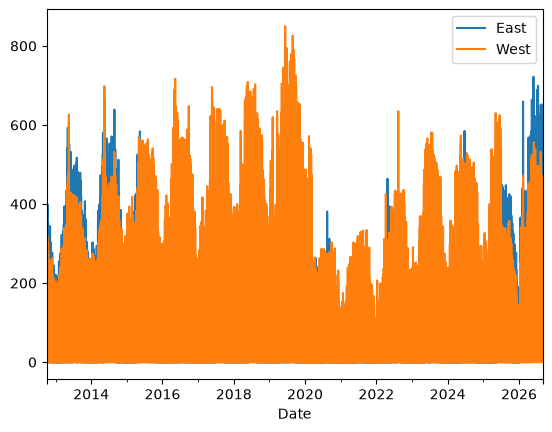

In [34]:
#A quoi ça ressemble

# un premier jet, pas terrible du tout
data[['East', 'West']].plot()


727


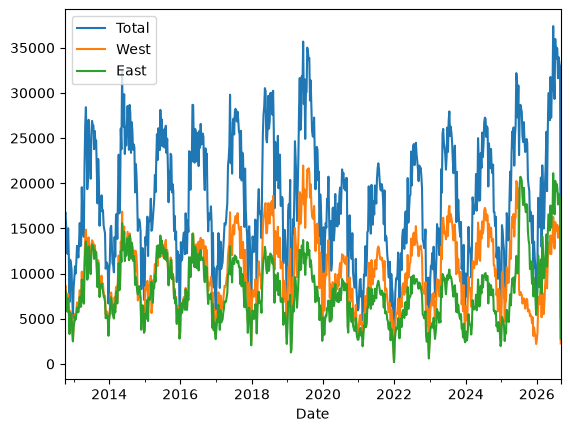

In [35]:
#resampling temporel

(data.resample("1W").sum()).plot()
print((data.resample("1W").sum()).shape[0])

#on a bien 87000~522*24*7

In [36]:
#découpage temporel

data1=data[data.index.year<=2017]

(0.0, 1100000.0)

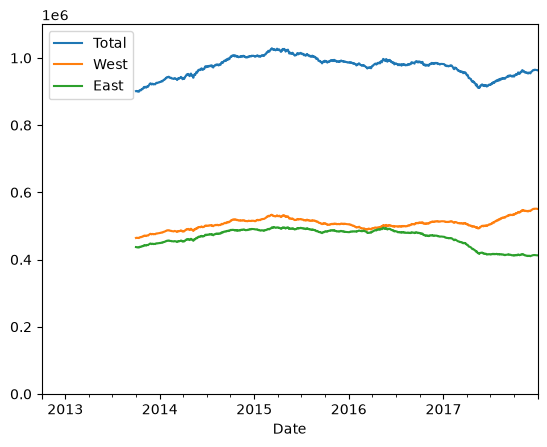

In [37]:
#évolution annuelle

annuelle=((data1.resample("1D").sum()).rolling(365)).sum()
annuelle.plot()
plt.ylim(0,1.1e6)

<Axes: xlabel='time'>

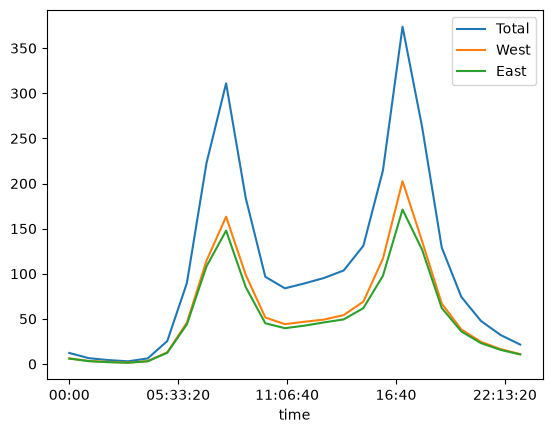

In [38]:
#profil journalier moyen

(data1.groupby(data1.index.time).mean()).plot()

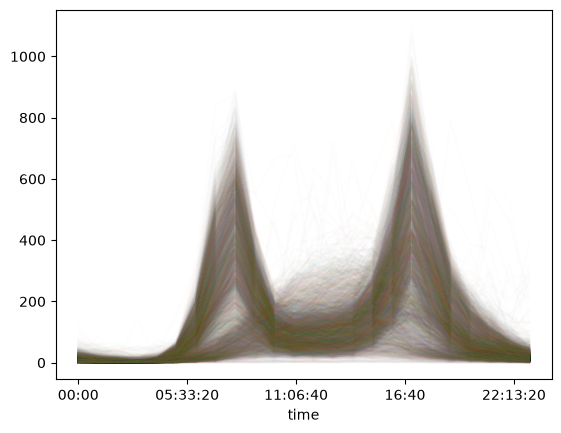

In [39]:
#une courbe par jour

pivoted = data.pivot_table(values='Total',index=data.index.time,columns=data.index.date)
pivoted.plot(legend=False, alpha=0.01)
plt.show()


In [40]:
#classification des jours
"""from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit_transform(pivoted.T.fillna(0))

plt.scatter(pca[:,0], pca[:,1])
plt.show()

#j'ai une erreur qui d'aprés ce que j'ai compris est du au fait que mon ordi ne fait pas confiance 
# à la fonction importé ou le module dont elle provient"""

"from sklearn.decomposition import PCA\n\npca = PCA(n_components=2).fit_transform(pivoted.T.fillna(0))\n\nplt.scatter(pca[:,0], pca[:,1])\nplt.show()\n\n#j'ai une erreur qui d'aprés ce que j'ai compris est du au fait que mon ordi ne fait pas confiance \n# à la fonction importé ou le module dont elle provient"

In [ ]:
#GaussianMixture
"""from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=2).fit_predict(pivoted.T.fillna(0))

plt.scatter(pca[:,0], pca[:,1], c=gm, cmap='coolwarm')
plt.show()

#meme erreur"""


"from sklearn.mixture import GaussianMixture\n\ngm = GaussianMixture(n_components=2).fit_predict(pivoted.T.fillna(0))\n\nplt.scatter(pca[:,0], pca[:,1], c=gm, cmap='coolwarm')\nplt.show()\n\n#meme erreur"

In [ ]:
#comparaison 

# il me faut les résutats précedents mais voila le code 
#pivoted.loc[:, gm == 0].plot(legend=False, alpha=0.01)
#plt.title("Cluster 0")
#plt.show()

#pivoted.loc[:, gm == 1].plot(legend=False, alpha=0.01)
#plt.title("Cluster 1")
#plt.show()


In [ ]:
#verification 
#meme probleme
"""dates = pd.DatetimeIndex(pivoted.columns)
dow = dates.dayofweek

plt.scatter(pca[:,0], pca[:,1], c=dow, cmap='viridis')
plt.show()
"""

In [ ]:
#les moutons noirs
""""odd = (gm == 1) & (dow < 5)
odd_dates = dates[odd]

pivoted[odd_dates].plot(legend=False)
plt.title("Jours atypiques")
plt.show()
"""